In [1]:
import sys
import os
import io
import pandas as pd
import numpy as np
from typing import Optional, Union
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath(".."))
from churn.datos import cargar_datos, tasa_por_grupo
from churn.eda import tasa_por_decil, graficar_tasa, margen_ic

In [2]:
margen_ic(0.5, 100)

0.098

In [3]:
df = cargar_datos("../data/dataset.csv")

In [4]:
promedio_global = df["churn"].mean()
promedio_global

np.float64(0.49562)

In [5]:
tasa_por_decil(df, 'months', 10)

,n_clientes,tasa_churn,margen_ic
months,,,
"(5.999, 8.0]",10002,0.330634,0.009220
"(8.0, 11.0]",16408,0.495917,0.007650
"(11.0, 12.0]",6033,0.618598,0.012257
"(12.0, 14.0]",10203,0.543664,0.009665
"(14.0, 16.0]",7435,0.517149,0.011359
"(16.0, 19.0]",10420,0.505278,0.009600
"(19.0, 23.0]",12481,0.508052,0.008771
"(23.0, 26.0]",7329,0.495566,0.011447
"(26.0, 33.0]",10933,0.510839,0.009370


In [6]:
segmento_meses = pd.cut(df["months"], bins=[0, 11, 24, df["months"].max()])
tasa_por_mes = tasa_por_grupo(df, segmento_meses, False)
tasa_por_mes

,n_clientes,tasa_churn
months,,
"(0, 11]",26410,0.433321
"(11, 24]",48901,0.530235
"(24, 61]",24689,0.493702


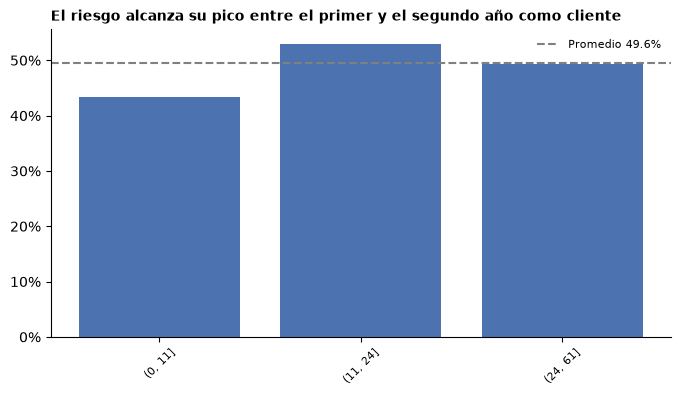

In [7]:

fig = graficar_tasa(
    tasa_por_mes,
    "El riesgo alcanza su pico entre el primer y el segundo año como cliente",
    promedio_global
)

In [8]:
numeric_cols = df.select_dtypes(include='number').columns.drop(['churn','Customer_ID'])

dif_tasas = pd.Series(
    {
        col: (t := tasa_por_decil(df, col, dropna=True)['tasa_churn']).max() - t.min()
        for col in numeric_cols
    },
    name="dif_tasa_churn"
).sort_values(ascending=False)

print(dif_tasas[:6])


months         0.287964
eqpdays        0.236783
hnd_price      0.214425
mou_Mean       0.146531
totmrc_Mean    0.131568
avg3mou        0.128536
Name: dif_tasa_churn, dtype: float64


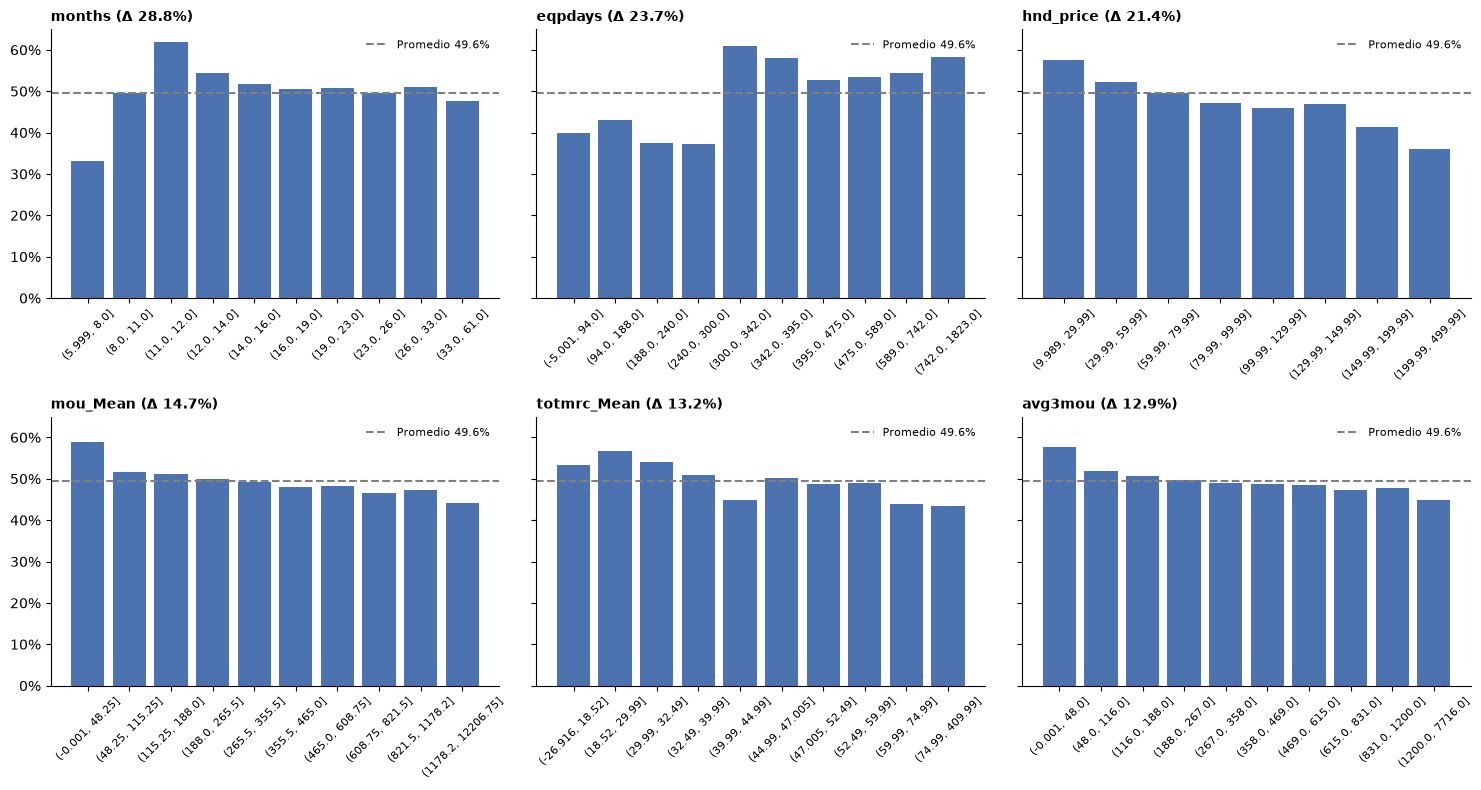

In [9]:
top_6_cols = dif_tasas.head(6).index

fig, axes = plt.subplots(2, 3, figsize=(15,8), sharey=True)

for col, ax in zip(top_6_cols, axes.flatten()):
    tabla_decil = tasa_por_decil(df, col, dropna=True)
    graficar_tasa(
        tabla=tabla_decil,
        titulo=f"{col} (Δ {dif_tasas[col]:.1%})",
        promedio=promedio_global,
        ax=ax
    )

plt.tight_layout()
plt.show()


### months: Total number of months in service
La tasa se mantiene abajo los primeros meses (5.999-11) luego comienza a subir alcanzando su pico en los meses 11-12 y después empieza a bajar poco a poco y se mantiene con diferencias mínimas.

### eqpdays: Number of days (age) of current mobile phone
La tasa se mantiene baja durante los días -0.5001 a 300 (aquí hay un error porque no tienen sentido valores negativos). Alcanza su pico en los días 300-342 y se mantiene por encima del promedio de ahí en adelante con diferencias mínimas entre deciles.
Entre el cuarto y el quinto decil hay un salto brusco, esto ocurre alrededor del día 300 (unos 10 meses).
Algo interesante es que months y eqpdays tienen su punto crítico cerca del año: months tiene el pico en 11-12 meses como cliente y eqpdays su salto está en ~10 meses de antigüedad del teléfono. Una hipótesis que conecta a ambas: en muchas telcos el teléfono viene con el contrato y se paga en mensualidades. Caundo se termina de pagar y el contrato vence, el cliente queda libre para irse, y además su teléfono ya está envejeciendo, así que busca uno nuevo, con la misma empresa o con la competencia. Eso sugiere una acción concreta: ofrecer la renovación del equipo antes de los ~300 días.

### hnd_price: Current handset price
La tasa de churn tiene su pico al principio (menor precio) y va disminuyendo conforme aumenta el precio teniendo su mínimo en los deciles más altos (mayores precios).

### mou_Mean: Mean number of monthly minutes of use
Como el hnd_price, la tasa baja conforme los deciles aumentan, en este caso, conforme el promedio de minutos de uso aumenta.

### totmrc_Mean: Mean total monthly recurring charge
Aquí la tasa va variando y la tendencia no es tan marcada pero aún así se nota que va bajando conforme el promedio del cargo mensual recurrente aumenta.

### avg3mou: Average monthly minutes of use over the previous three months
Aquí se ve un comportamiento que sigue la tendencia de mou_Mean, conforme aumenta el promedio de minutos, disminuye la tasa de churn.

In [10]:
# custcare_Mean: Mean number of customer care calls
tabla_formateada = tasa_por_decil(df, 'custcare_Mean',dropna = True)
tabla_formateada["tasa_churn"] = tabla_formateada["tasa_churn"].map(lambda x: f"{x:.1%}")
tabla_formateada

,n_clientes,tasa_churn,margen_ic
custcare_Mean,,,
"(-0.001, 0.333]",62905,51.5%,0.003906
"(0.333, 1.0]",8887,49.1%,0.010394
"(1.0, 2.333]",9178,46.6%,0.010206
"(2.333, 5.333]",9472,45.3%,0.010024
"(5.333, 675.333]",9558,44.1%,0.009954


In [11]:
uso_terciles = pd.qcut(
    df["mou_Mean"],
    3,
    labels=["Bajo uso", "Uso medio", "Alto uso"],
    duplicates="drop"
)

llamo_soporte = df["custcare_Mean"] > 0

resumen = (
    df.groupby([uso_terciles.rename("nivel_uso"), llamo_soporte.rename("llamo_soporte")], observed=True)
    .agg(
        n_clientes=('churn', 'count'),
        tasa_churn=('churn', 'mean')
    )
    .reset_index()
)

tabla_comparativa = resumen.pivot(
    index="nivel_uso", 
    columns="llamo_soporte", 
    values=["n_clientes","tasa_churn"]
).rename(columns={False: "No llamó soporte", True: "Sí llamó soporte"})

tabla_formateada = tabla_comparativa.copy()
tabla_formateada["tasa_churn"] = tabla_formateada["tasa_churn"].map(lambda x: f"{x:.1%}")

display(tabla_formateada)

n_clientes                        tasa_churn  \
llamo_soporte No llamó soporte Sí llamó soporte No llamó soporte   
nivel_uso                                                          
Bajo uso               26468.0           6757.0            53.7%   
Uso medio              18625.0          14594.0            49.8%   
Alto uso               10312.0          22887.0            49.7%   

                                
llamo_soporte Sí llamó soporte  
nivel_uso                       
Bajo uso                 52.4%  
Uso medio                47.5%  
Alto uso                 44.7%

Sin estratificar, si se promedian los tres niveles con sus conteos, la diferencia total es de unos -4.8 puntos. Dentro de los estratos, la diferencia promedio baja a unos -2.9 puntos. Esro quiere decir:
1. El uso explica una parte de la relación (aproximadamente el 40% de la brecha), pero no toda.
2. No hay inversión (no es Simpson): en los tres niveles, los que llaman se van menos.
3. El efecto depende del uso: casi nulo en uso bajo y más claro en uso alto.

Lo que sí se puede recomendar a partir de esto:
* Analizar el contenido de las llamadas: motivo, ofertas hechas, resolución.
* Si se quiere saber si el contacto proactivo retiene, hacer un experimento: contactar a un grupo aleatorio de clientes de alto uso y compararlo con un grupo de control.

In [12]:
# Matriz de correlación
corr_matrix = (
    df[numeric_cols]
    .corr(method="spearman")
)

In [13]:
# Máscara para conservar solo el triángulo superior (excluyendo diagonal k=1)
mask = np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)

# Filtrar, aplanar y ordenar por magnitud
pares_alta_corr = (
    corr_matrix.where(mask)
    .stack()
    .rename("spearman_r")
    .loc[lambda r: r.abs() > 0.9]
    .reset_index()
    .rename(columns={'level_0': 'var_1', 'level_1': 'var_2'})
    .assign(abs_r=lambda d: d['spearman_r'].abs())
    .sort_values(by='abs_r', ascending=False)
    .drop(columns='abs_r')
)

display(pares_alta_corr)

,var_1,var_2,spearman_r
45,totcalls,adjqty,0.999470
46,totmou,adjmou,0.999451
14,plcd_vce_Mean,attempt_Mean,0.999364
24,comp_vce_Mean,complete_Mean,0.999166
37,peak_dat_Mean,mou_pead_Mean,0.999160
25,comp_dat_Mean,mou_cdat_Mean,0.998889
41,opk_dat_Mean,mou_opkd_Mean,0.998804
28,ccrndmou_Mean,cc_mou_Mean,0.998112
5,ovrmou_Mean,ovrrev_Mean,0.997827
48,totrev,adjrev,0.995622


In [14]:
pares_alta_corr.shape

(60, 3)

In [15]:
familias_variables = {
    "Ingresos y Facturación": [
        "rev_Mean", "avg3rev", "avg6rev", "avgrev", "totrev", "adjrev"
    ],
    "Excedentes (Overage)": [
        "ovrmou_Mean", "ovrrev_Mean", "vceovr_Mean"
    ],
    "Volumen de Minutos (Voz y General)": [
        "mou_Mean", "avg3mou", "avg6mou", "avgmou", "totmou", "adjmou",
        "mou_cvce_Mean", "mou_peav_Mean", "mou_opkv_Mean", "mou_rvce_Mean",
        "mouowylisv_Mean", "mouiwylisv_Mean", "inonemin_Mean"
    ],
    "Conteo y Estado de Llamadas": [
        "totcalls", "adjqty", "avgqty", "avg3qty", "avg6qty",
        "attempt_Mean", "complete_Mean", "plcd_vce_Mean", "comp_vce_Mean",
        "peak_vce_Mean", "opk_vce_Mean", "recv_vce_Mean", "unan_vce_Mean",
        "owylis_vce_Mean", "iwylis_vce_Mean"
    ],
    "Uso y Sesiones de Datos": [
        "plcd_dat_Mean", "comp_dat_Mean", "mou_cdat_Mean",
        "peak_dat_Mean", "mou_pead_Mean", "opk_dat_Mean", "mou_opkd_Mean"
    ],
    "Soporte y Atención al Cliente": [
        "custcare_Mean", "cc_mou_Mean", "ccrndmou_Mean"
    ],
    "Dispositivos y Equipamiento": [
        "phones", "models"
    ]
}

In [16]:
# Invertir el diccionario para mapeo: {columna: familia}
var_a_familia = {
    var: familia 
    for familia, vars_list in familias_variables.items() 
    for var in vars_list
}

# Asignar familias a tabla de correlaciones
pares_alta_corr["familia_1"] = pares_alta_corr["var_1"].map(var_a_familia).fillna("Otros")
pares_alta_corr["familia_2"] = pares_alta_corr["var_2"].map(var_a_familia).fillna("Otros")
pares_alta_corr["misma_familia"] = pares_alta_corr["familia_1"] == pares_alta_corr["familia_2"]

display(pares_alta_corr)

,var_1,var_2,spearman_r,familia_1,familia_2,misma_familia
45,totcalls,adjqty,0.999470,Conteo y Estado de Llamadas,Conteo y Estado de Llamadas,True
46,totmou,adjmou,0.999451,Volumen de Minutos (Voz y General),Volumen de Minutos (Voz y General),True
14,plcd_vce_Mean,attempt_Mean,0.999364,Conteo y Estado de Llamadas,Conteo y Estado de Llamadas,True
24,comp_vce_Mean,complete_Mean,0.999166,Conteo y Estado de Llamadas,Conteo y Estado de Llamadas,True
37,peak_dat_Mean,mou_pead_Mean,0.999160,Uso y Sesiones de Datos,Uso y Sesiones de Datos,True
25,comp_dat_Mean,mou_cdat_Mean,0.998889,Uso y Sesiones de Datos,Uso y Sesiones de Datos,True
41,opk_dat_Mean,mou_opkd_Mean,0.998804,Uso y Sesiones de Datos,Uso y Sesiones de Datos,True
28,ccrndmou_Mean,cc_mou_Mean,0.998112,Soporte y Atención al Cliente,Soporte y Atención al Cliente,True
5,ovrmou_Mean,ovrrev_Mean,0.997827,Excedentes (Overage),Excedentes (Overage),True
48,totrev,adjrev,0.995622,Ingresos y Facturación,Ingresos y Facturación,True


In [17]:
import pandas as pd

# 1. Crear un DataFrame base con todas las variables y sus familias
df_variables = pd.DataFrame(
    list(var_a_familia.items()), 
    columns=['variable', 'familia']
).set_index('variable')

# 2. Calcular la cantidad de nulos de cada variable en el DataFrame original
nulos_series = df[df_variables.index].isna().sum().rename('cantidad_nulos')

# 3. Unir la señal y los nulos al DataFrame base
df_evaluacion = (
    df_variables
    .join(dif_tasas.rename('senal'))
    .join(nulos_series)
    .reset_index()
)

# 4. Ordenar y filtrar
variables_a_conservar = (
    df_evaluacion
    # Ordenar por familia, luego mayor señal (False), luego menores nulos (True)
    .sort_values(
        by=['familia', 'senal', 'cantidad_nulos'], 
        ascending=[True, False, True],
        na_position='last'  # Si alguna no tiene señal, se va al fondo
    )
    # Quedarse solo con la primera fila de cada familia (la que cumple los criterios)
    .drop_duplicates(subset=['familia'], keep='first')
    .reset_index(drop=True)
)

display(variables_a_conservar)

,variable,familia,senal,cantidad_nulos
0,complete_Mean,Conteo y Estado de Llamadas,0.127284,0
1,models,Dispositivos y Equipamiento,0.058746,1
2,ovrmou_Mean,Excedentes (Overage),0.048113,357
3,adjrev,Ingresos y Facturación,0.119853,0
4,custcare_Mean,Soporte y Atención al Cliente,0.074373,0
5,plcd_dat_Mean,Uso y Sesiones de Datos,0.043223,0
6,mou_Mean,Volumen de Minutos (Voz y General),0.146531,357


Aplicando también el criterio de explicabilidad de negocio, ajusté a las representantes más limpias:
1. Ingresos y Facturación: rev_Mean (ingreso mensual promedio).
2. Volumen de Minutos: mou_Mean (minutos de uso mensual promedio).
3. Conteo de Llamadas: complete_Mean (llamadas completadas, mucho mejor para medir uso real que los meros intentos).
4. Excedentes: ovrrev_Mean (ingreso por excedentes, "cuánto pagan de penalización", duele más al usuario y explica mejor el churn).
5. Datos: comp_dat_Mean (llamadas de datos completadas).
6. Atención al Cliente: custcare_Mean (interacciones con soporte)
7. Dispositivos: phones (cantidad de equipos).

#### Correlaciones cruzadas (Redundancia entre familias)
Revisando la tabla de correlaciones donde misma_familia es False, noté un patrón entre la familia de Volumen de Minutos y Conteo de Llamadas:
- avg3mou (minutos) y avg3qty (llamadas) tienen un |r| = 0.931.
- totcalls (llamadas) y totmou (minutos) tienen un |r| = 0.930.
- mou_cvce_Mean (minutos) y complete_Mean (llamadas) tienen un |r| = 0.903.

**Conclusión**: En la telefonía, el número de llamadas que haces y los minutos que hablas son prácticamente la misma señal de comportamiento. Meter ambas al modelo (ej. mou_Mean y complete_Mean) generará multicolinealidad.
**Decisión**: Eligo solo una familia. Por lo general, los minutos (mou_Mean) capturan mejor el volumen de la red, así que puedo descartar complete_Mean.

#### Lista Final de Variables (Entrada del Modelo)
Combinando las representantes de familia y las variables huérfanas presentes en el diccionario, esta es la lista definitiva de columnas a considerar:

**1. Representantes de Familia:**
- rev_Mean
- mou_Mean
- ovrrev_Mean
- comp_dat_Mean
- custcare_Mean
- phones

**2. Las Huérfanas (Variables No Agrupadas):**
- Las críticas de ciclo de vida: months y eqpdays.
- Variaciones de tendencia: change_mou y change_rev.
- Calidad de red (Fricción): drop_vce_Mean, drop_dat_Mean, drop_blk_Mean, blck_vce_Mean, blck_dat_Mean, unan_dat_Mean.
- Planes y características de la cuenta: totmrc_Mean (cargo recurrente base), uniqsubs, actvsubs, roam_Mean, datovr_Mean.
- Servicios adicionales: da_Mean (asistencia de directorio), recv_sms_Mean, callfwdv_Mean, callwait_Mean, threeway_Mean.
- Demográficos y de equipo: hnd_price, adults, income, numbcars, forgntvl, truck, rv, lor.

# Hallazgos Principales

## 1. El riesgo de abandono alcanza su pico crítico al cumplir un año como cliente
- **Evidencia:** La tasa de churn pasa de un 33.1% en los primeros meses hasta dispararse al 61.8% en el grupo de 11 a 12 meses.
- **Hipótesis:** Es altamente probable que los contratos iniciales forzosos duren 12 meses. Al terminar el plazo, el cliente queda libre de penalización y se abre a promociones de la competencia.
- **Acción posible:** Disparar campañas proactivas de fidelización o renovación de contrato en el mes 10, antes de que el cliente tome la decisión de irse.
- **Precaución:** Presenta un claro sesgo de supervivencia. Los clientes con más de 24 meses muestran tasas más bajas simplemente porque ya sobrevivieron al filtro crítico del primer año.

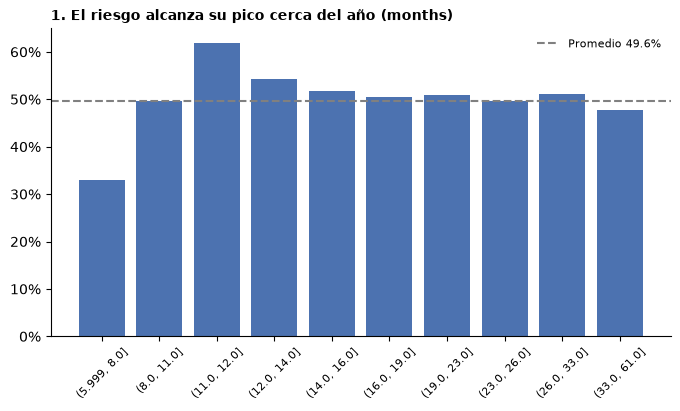

In [18]:
# 1. Hallazgo: Months (Antigüedad)
tabla_months = tasa_por_decil(df, 'months', dropna=True)
fig = (graficar_tasa(tabla_months, "1. El riesgo alcanza su pico cerca del año (months)", promedio_global))

## 2. La necesidad de un teléfono nuevo dispara la salida del cliente
- **Evidencia:** Se observa un salto brusco en la tasa de churn al superar los ~300 días de antigüedad del teléfono (eqdays), superando de ahí en adelante el promedio global.
- **Hipótesis:** Alrededor de los 10 meses el equipo empieza a mostrar desgaste (batería, lentitud) o el cliente termina de pagarlo. El deseo de un equipo nuevo actúa como catalizador para evaluar cambiar de compañía.
- **Acción posible:** Ofrecer upgrades (renovación de equipo con descuento) justo en el mes 9 de vida del teléfono, amarrando un nuevo ciclo de retención.
- **Precaución:** La variable tiene valores negativos imposibles que representan ruido.

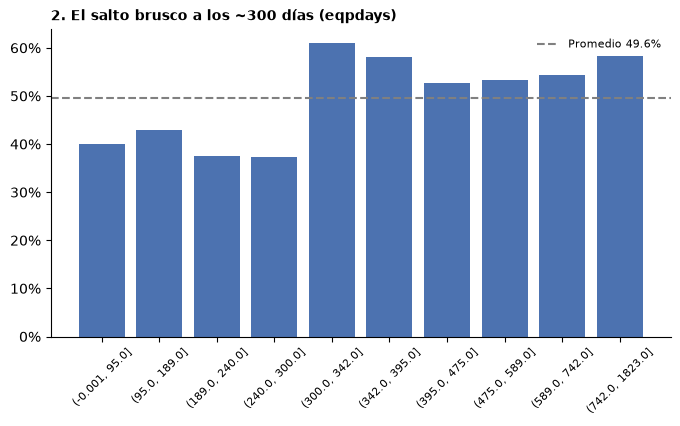

In [19]:
df_eqp = df[df['eqpdays'] >= 0]
tabla_eqp = tasa_por_decil(df_eqp, 'eqpdays', dropna=True)
fig = (graficar_tasa(tabla_eqp, "2. El salto brusco a los ~300 días (eqpdays)", promedio_global))

## 3. En clientes de alto uso, los que llamaron a soporte se van 5 puntos menos
- **Evidencia:** Globalmente, la tasa cae 51.8% a 46.8% si el cliente llama a soporte. Sin embargo, al estratificar, vemos que en clientes de *Alto Uso*, la verdadera diferencia entre llamar y no llamar es de -5.0 puntos (49.7% vs 44.7%).
- **Hipótesis:** El soporte técnico sí ayuda a salvar relaciones resolviendo conflictos, pero los clientes de *Bajo Uso* que no llaman es porque ya abandonaron mentalmente el servicio (causalidad inversa).
- **Acción posible:** Diseñar un experimento (Test A/B): contactar proactivamente desde soporte a clientes de *Alto Uso* que nunca han reportado fallas para ver si esa intervención reduce su churn empíricamente.
- **Precaución:** Hay sesgo de confusión. El alto uso provoca que llamen más y que se vayan menos. Forzar a un cliente a llamar a soporte no reducirá mágicamente su riesgo de irse.

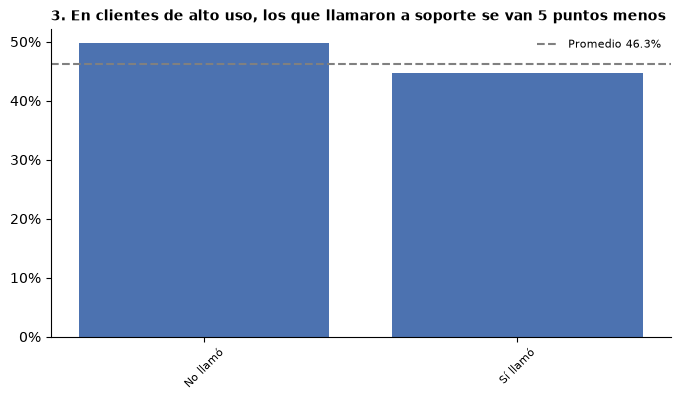

In [20]:
# 3. Hallazgo: Soporte Estratificado (Alto uso)
# Filtramos solo el tercil de "Alto uso" para la gráfica
limite_alto_uso = df['mou_Mean'].quantile(0.666)
df_alto_uso = df[df['mou_Mean'] > limite_alto_uso].copy()
df_alto_uso['Llamo_Soporte'] = np.where(df_alto_uso['custcare_Mean'] > 0, "Sí llamó", "No llamó")
tabla_soporte = df_alto_uso.groupby('Llamo_Soporte')['churn'].mean().to_frame(name='tasa_churn')
fig = (graficar_tasa(tabla_soporte, "3. En clientes de alto uso, los que llamaron a soporte se van 5 puntos menos", df_alto_uso['churn'].mean()))

## 4. Los usuarios de teléfonos básicos son los menos leales
- **Evidencia:** Al evaluar el precio del teléfono (`hnd_price`), la diferencia de la tasa entre el decil de equipos más baratos y los más caros es enorme: 21.4 puntos de separación.
- **Hipótesis:** Los usuarios de teléfonos baratos tienen mayor sensibilidad al precio o sufren una peor experiencia de red, lo que los hace querer cambiarse rápidamente.
- **Acción posible:** Redirigir el presupuesto de retención hacia clientes con mayor riesgo de irse (teléfonos de entrada).
- **Precaución:** Es un análisis univariado. El precio del teléfono podría estar fuertemente asociado a variables sociodemográficas como el nivel de ingresos (`income`) o el tipo de plan contratado.

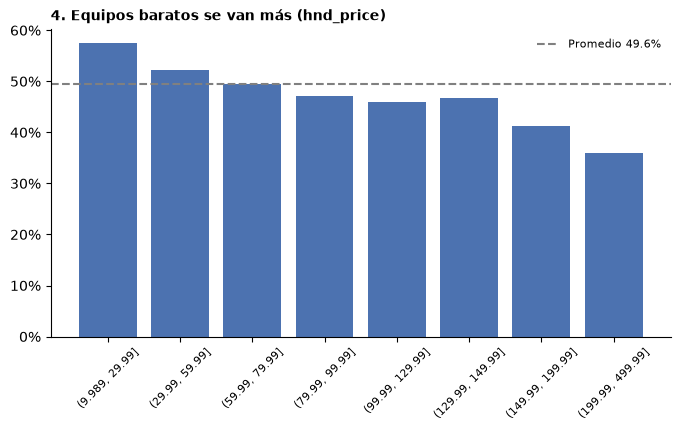

In [21]:
# 4. Hallazgo: Precio del equipo
tabla_precio = tasa_por_decil(df, 'hnd_price', dropna=True)
fig = (graficar_tasa(tabla_precio, "4. Equipos baratos se van más (hnd_price)", promedio_global))

## 5. El grupo NA en hnd_webcap es de alto riesgo
- **Evidencia:** En la capacidad web del equipo (`hnd_webcap`), el grupo `NA` tiene 10,188 clientes y una tasa del 59.2%, muy por encima del promedio por 9.6 puntos porcentuales. La mediana del precio del teléfono en el grupo NA es de ~$30, contra ~$130 en WCMB"
- **Hipótesis:** Al ser un grupo con una tasa de cancelación muy alta, se considera como un grupo de alto riesgo. Este grupo podrías ser de dispositivos de gama muy baja y eso explicaría su alta tasa de churn.
- **Acción posible:** Se refuerza el redirigir el presupuesto de retención hacia clientes con mayor riesgo de irse (teléfonos de entrada) incentivándolos con promociones a actualizar sus dispositivos por otros de gama más alta.
- **Precaución:** Al no ser el grupo de mayor tamaño se podría estar enfocando en pocos clientes con poco potencial de adquirir un mejor dispositivo. Pensar una buena estrategia de venta para que mejoren su dispositivo sin comprometer las ganancias de la compañía, es clave.

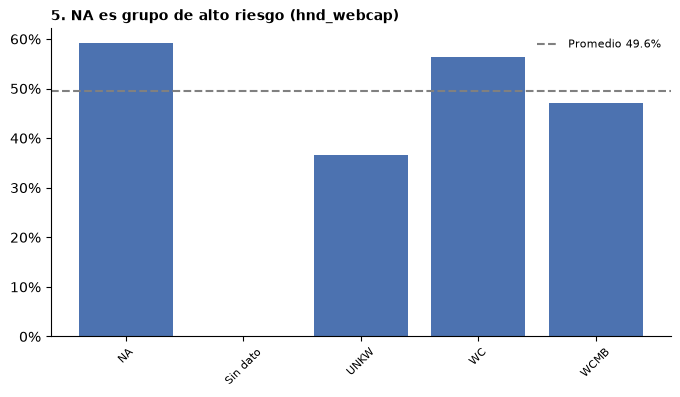

In [22]:
# 5.
# Rellenar los nulos con un texto explícito antes de agrupar
df_webcap = df.copy()
df_webcap['hnd_webcap'] = df_webcap['hnd_webcap'].fillna("Sin dato")

tabla_webcap = df_webcap.groupby('hnd_webcap')['churn'].mean().to_frame(name='tasa_churn')
fig = (graficar_tasa(tabla_webcap, "5. NA es grupo de alto riesgo (hnd_webcap)", promedio_global))

In [23]:
df.groupby('hnd_webcap')['hnd_price'].median()

hnd_webcap
NA       29.98999
UNKW          NaN
WC       29.98999
WCMB    129.98999
Name: hnd_price, dtype: float64

In [24]:
def comparar_nulos(df: pd.DataFrame, columna: str) -> pd.DataFrame:
    """Compara la tasa de churn entre registros con y sin dato (nulos)."""
    es_nulo = df[columna].isna().replace({True: 'Sin dato /Nulo', False: 'Con dato'})

    resumen = df.groupby(es_nulo.rename("estado_dato"))['churn'].agg(
        n_clientes='count',
        tasa_churn='mean'
    ).reset_index()

    resumen['tasa_churn'] = resumen['tasa_churn'].map(lambda x: f"{x:.1%}")

    print(f"--- Impacto de nulos en {columna} ---")
    display(resumen)
    print()

In [25]:
comparar_nulos(df, 'hnd_price')
comparar_nulos(df, 'avg6rev')

--- Impacto de nulos en hnd_price ---


,estado_dato,n_clientes,tasa_churn
0,Con dato,99153,49.7%
1,Sin dato /Nulo,847,36.7%



--- Impacto de nulos en avg6rev ---


,estado_dato,n_clientes,tasa_churn
0,Con dato,97161,49.8%
1,Sin dato /Nulo,2839,40.2%


In [26]:
es_nulo = df['hnd_price'].isna().replace({True: 'Sin dato /Nulo', False: 'Con dato'})
df.groupby(es_nulo.rename("estado_dato"))['eqpdays'].agg(
    n_clientes='count',
    mediana_eqpdays='median'
)

,n_clientes,mediana_eqpdays
estado_dato,,
Con dato,99153,343.0
Sin dato /Nulo,846,52.0


hnd_price (Precio del equipo): Si un cliente no tiene precio registrado, la hipótesis en telefonía es que trajo su propio equipo. Estos clientes tienen una mediana de 52 días de eqpdays (contra 342 del total). Son clientes con teléfono recién adquirido, un teléfono nuevo es de bajo riesgo. La tasa de churn es baja 36.7%.

avg6rev (Ingreso promedio de los últimos 6 meses): Si este dato es nulo, es porque son clientes recientes cuyo historial de facturación probablemente no alcanza para el promedio. Aquí el nulo es un "espejo" de la variable antigüedad (months).

In [27]:
# Contar cuántos valores negativos hay
negativos_eqp = (df['eqpdays'] < 0).sum()
negativos_rev = (df['rev_Mean'] < 0).sum()
negativos_totmrc_Mean = (df['totmrc_Mean'] < 0).sum()
negativos_avg6rev = (df['avg6rev'] < 0).sum()

print(f"Filas con eqpdays negativo: {negativos_eqp} ({(negativos_eqp/len(df)):.2%})")
print(f"Filas con ingresos negativos: {negativos_rev} ({(negativos_rev/len(df)):.2%})")
print(f"Filas con totmrc_Mean negativos: {negativos_totmrc_Mean} ({(negativos_totmrc_Mean/len(df)):.2%})")
print(f"Filas con avg6rev negativos: {negativos_avg6rev} ({(negativos_avg6rev/len(df)):.2%})")

Filas con eqpdays negativo: 133 (0.13%)
Filas con ingresos negativos: 5 (0.01%)
Filas con totmrc_Mean negativos: 23 (0.02%)
Filas con avg6rev negativos: 3 (0.00%)


In [28]:
df[df['eqpdays'] < 0]['eqpdays'].min()

np.float64(-5.0)

In [29]:
df[df['rev_Mean'] < 0]['rev_Mean'].min()

np.float64(-6.1675)

In [30]:
df[df['totmrc_Mean'] < 0]['totmrc_Mean'].min()

np.float64(-26.915)

In [31]:
df[df['avg6rev'] < 0]['avg6rev'].min()

np.float64(-2.0)

Los valores negativos de eqpdays son pocos y cercanos a ceros, por lo que considero que la mejor estrategia es pasarlos a ceros. Se asumiría que los días negativos representan equipos adquiridos justo antes de la activación. Se limitaría el valor mínimo a 0 para mantener la validez lógica sin perder la fila entera.

Los valores negativos en rev_Mean, totmrc_Mean y avg6revrepresentan el 0.01% del dataset, intentar integrarlos no sería tan práctico. Son filas sucias y el dataset tiene miles de registros sanos. Al representar una fracción irrelevante del total de clientes (<0.1%), decidiría dejar estas filas como NaN e imputarlas para garantizar la calidad del dataset sin afectar significativamente la representatividad ni el entrenamiento del modelo.